# NLCD Data Exploration

Annual NLCD covers the CONUS, while this project’s NHDPlus catchments cover the Great Lakes region. This notebook inventories the available NLCD years, checks raster metadata, and compares the earliest and latest years within the actual NHDPlus catchment polygons.

The 30 m rasters are read as nearest-neighbor overviews to keep memory use low. Catchment polygons mask the overview maps and class-share summaries; percentages are therefore approximate at the reduced display resolution. Raw inputs are read-only.

In [32]:
# Load the libraries needed to explore NLCD rasters and the project catchment extent.

from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import rasterio
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.transform import Affine
from rasterio.warp import transform_bounds
from rasterio.windows import Window, bounds as window_bounds, from_bounds

In [33]:
# Find the annual NLCD land-cover rasters in the raw data folder.

raw_candidates = [
    Path("../data/raw/nlcd"),
    Path("data/raw/nlcd"),
]

raw_dir = next((path.resolve() for path in raw_candidates if path.is_dir()), None)

if raw_dir is None:
    searched = ", ".join(str(path.resolve()) for path in raw_candidates)
    raise FileNotFoundError(f"NLCD raw data folder not found. Searched: {searched}")

raster_files = sorted(
    path for path in raw_dir.rglob("*")
    if path.suffix.lower() in {".tif", ".tiff"}
)

if not raster_files:
    raise FileNotFoundError(f"No NLCD TIFF rasters found under {raw_dir}")


def year_from_path(path):
    return next(
        int(part) for part in path.stem.split("_")
        if part.isdigit() and len(part) == 4
    )


print("NLCD directory:", raw_dir)
print("Total annual rasters:", len(raster_files))

for collection in sorted({path.parent.name for path in raster_files}):
    collection_years = sorted(
        year_from_path(path)
        for path in raster_files
        if path.parent.name == collection
    )
    print(
        f"  {collection}: {len(collection_years)} rasters, "
        f"{collection_years[0]}-{collection_years[-1]}"
    )

print("Available years:", ", ".join(str(year_from_path(path)) for path in raster_files))

NLCD directory: /home/rasheedr/graph-based-water-quality/data/raw/nlcd
Total annual rasters: 30
  Annual_NLCD_LndCov_1985-1994_CU_C1V2: 10 rasters, 1985-1994
  Annual_NLCD_LndCov_1995-2004_CU_C1V2: 10 rasters, 1995-2004
  Annual_NLCD_LndCov_2005-2014_CU_C1V2: 10 rasters, 2005-2014
Available years: 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014


In [34]:
# Compare raster dimensions, resolution, data type, and NoData values across years.

metadata_rows = []
for raster_path in raster_files:
    with rasterio.open(raster_path) as raster:
        crs_authority = raster.crs.to_authority()
        crs_name = " ".join(raster.crs.to_wkt().split('"')[1].split())
        metadata_rows.append({
            "year": year_from_path(raster_path),
            "collection": raster_path.parent.name,
            "width": raster.width,
            "height": raster.height,
            "bands": raster.count,
            "data type": raster.dtypes[0],
            "pixel size (m)": raster.res[0],
            "NoData": raster.nodata,
            "CRS": ":".join(crs_authority) if crs_authority else crs_name,
        })

raster_metadata = pd.DataFrame(metadata_rows).sort_values("year").reset_index(drop=True)
display(raster_metadata)

print("Raster shape consistency:")
print("  Unique dimensions:", raster_metadata[["width", "height"]].drop_duplicates().values.tolist())
print("  Unique pixel sizes:", sorted(raster_metadata["pixel size (m)"].unique()))
print("  Unique coordinate systems:", raster_metadata["CRS"].unique().tolist())

,year,collection,width,height,bands,data type,pixel size (m),NoData,CRS
0,1985,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
1,1986,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
2,1987,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
3,1988,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
4,1989,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
5,1990,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
6,1991,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
7,1992,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
8,1993,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84
9,1994,Annual_NLCD_LndCov_1985-1994_CU_C1V2,160000,105000,1,uint8,30.0,250.0,AEA WGS84


Raster shape consistency:
  Unique dimensions: [[160000, 105000]]
  Unique pixel sizes: [np.float64(30.0)]
  Unique coordinate systems: ['AEA WGS84']


NHDPlus catchments loaded: 105849
NHDPlus catchment CRS: EPSG:4269
1985 overview: (1555, 2400); pixels inside catchments: 682,091
2014 overview: (1555, 2400); pixels inside catchments: 682,091


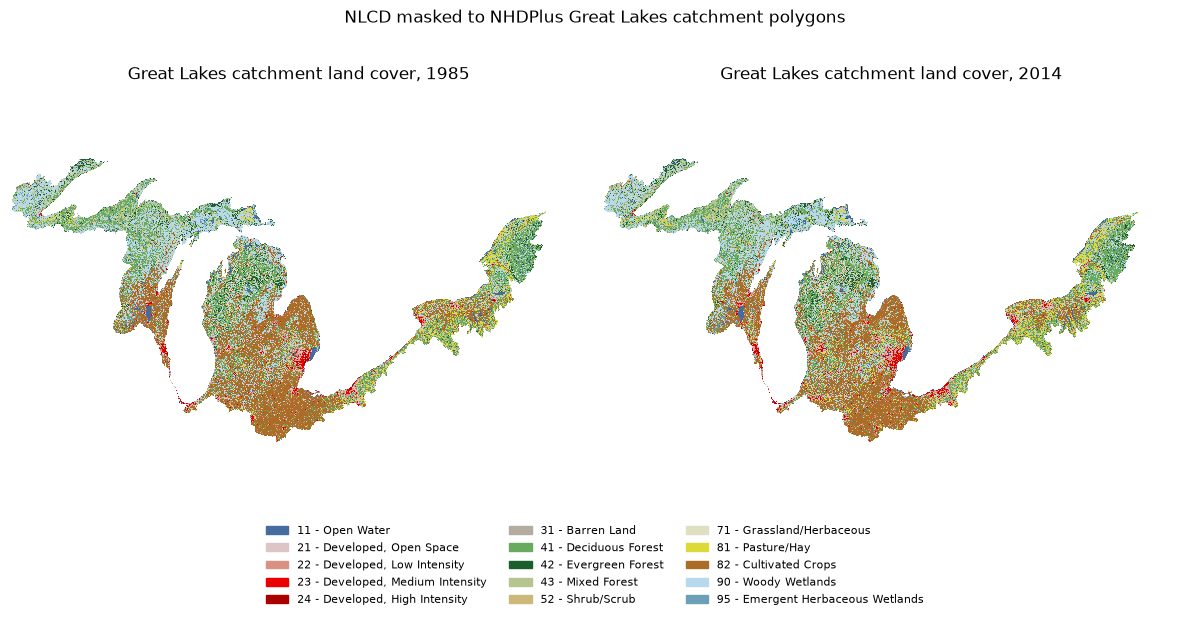

Approximate class share within the catchments at overview resolution (%):


,1985,2014
Land-cover class,,
11 - Open Water,3.12,3.09
"21 - Developed, Open Space",4.35,4.55
"22 - Developed, Low Intensity",3.92,4.81
"23 - Developed, Medium Intensity",1.44,2.02
"24 - Developed, High Intensity",0.42,0.57
31 - Barren Land,0.27,0.35
41 - Deciduous Forest,21.71,21.55
42 - Evergreen Forest,3.83,3.64
43 - Mixed Forest,6.52,6.68


In [35]:
# Compare land-cover patterns within the actual Great Lakes catchment polygons.

land_cover_labels = {
    11: "Open Water",
    12: "Perennial Ice/Snow",
    21: "Developed, Open Space",
    22: "Developed, Low Intensity",
    23: "Developed, Medium Intensity",
    24: "Developed, High Intensity",
    31: "Barren Land",
    41: "Deciduous Forest",
    42: "Evergreen Forest",
    43: "Mixed Forest",
    52: "Shrub/Scrub",
    71: "Grassland/Herbaceous",
    81: "Pasture/Hay",
    82: "Cultivated Crops",
    90: "Woody Wetlands",
    95: "Emergent Herbaceous Wetlands",
}

land_cover_colors = {
    11: "#466b9f", 12: "#d1def8", 21: "#dec5c5", 22: "#d99282",
    23: "#eb0000", 24: "#ab0000", 31: "#b3ac9f", 41: "#68ab5f",
    42: "#1c5f2c", 43: "#b5c58f", 52: "#ccb879", 71: "#dfdfc2",
    81: "#dcd939", 82: "#ab6c28", 90: "#b8d9eb", 95: "#6c9fb8",
}

catchment_relative_path = Path(
    "NHDPlusCatchments/NHDPlus04/NHDPlusCatchment/Catchment.shp"
)
catchment_candidates = [
    Path("../data/raw/nhdplus") / catchment_relative_path,
    Path("data/raw/nhdplus") / catchment_relative_path,
]
catchment_path = next(
    (path.resolve() for path in catchment_candidates if path.is_file()),
    None,
)
if catchment_path is None:
    searched = ", ".join(str(path.resolve()) for path in catchment_candidates)
    raise FileNotFoundError(f"NHDPlus catchment shapefile not found. Searched: {searched}")

catchment_info = pyogrio.read_info(catchment_path)
catchments = gpd.read_file(catchment_path, columns=[])
with rasterio.open(raster_files[0]) as reference_raster:
    catchments = catchments.to_crs(reference_raster.crs)
catchment_geometries = catchments.geometry
print("NHDPlus catchments loaded:", len(catchments))
print("NHDPlus catchment CRS:", catchment_info["crs"])


def read_land_cover_overview(path, max_dimension=2400):
    with rasterio.open(path) as raster:
        projected_bounds = transform_bounds(
            catchment_info["crs"],
            raster.crs,
            *catchment_info["total_bounds"],
        )
        window = from_bounds(*projected_bounds, transform=raster.transform)
        window = window.round_offsets().round_lengths()
        window = window.intersection(Window(0, 0, raster.width, raster.height))
        if window.width <= 0 or window.height <= 0:
            raise ValueError(f"Catchment extent does not overlap {path.name}")

        scale = max(window.width, window.height) / max_dimension
        output_shape = (
            max(1, round(window.height / scale)),
            max(1, round(window.width / scale)),
        )
        overview_transform = raster.window_transform(window) * Affine.scale(
            window.width / output_shape[1],
            window.height / output_shape[0],
        )
        values = raster.read(
            1,
            window=window,
            out_shape=output_shape,
            resampling=Resampling.nearest,
        )
        catchment_mask = rasterize(
            (
                (geometry, 1)
                for geometry in catchment_geometries
                if geometry is not None and not geometry.is_empty
            ),
            out_shape=output_shape,
            transform=overview_transform,
            fill=0,
            default_value=1,
            dtype="uint8",
        ).astype(bool)
        metadata = {
            "nodata": raster.nodata,
            "bounds": window_bounds(window, raster.transform),
        }
    return values, metadata, catchment_mask


year_to_path = {year_from_path(path): path for path in raster_files}
available_years = sorted(year_to_path)
comparison_years = [available_years[0], available_years[-1]]
overviews = {}
overview_metadata = {}
catchment_masks = {}

for year in comparison_years:
    (
        overviews[year],
        overview_metadata[year],
        catchment_masks[year],
    ) = read_land_cover_overview(year_to_path[year])
    print(
        f"{year} overview: {overviews[year].shape}; "
        f"pixels inside catchments: {catchment_masks[year].sum():,}"
    )

valid_values = {}
class_codes = set()
for year in comparison_years:
    values = overviews[year]
    nodata = overview_metadata[year]["nodata"]
    valid = catchment_masks[year]
    if nodata is not None:
        valid &= values != nodata
    valid_values[year] = values[valid]
    class_codes.update(np.unique(valid_values[year]).tolist())

class_codes = np.array(sorted(class_codes))
class_names = [
    f"{int(code)} - {land_cover_labels.get(int(code), 'Other/unclassified')}"
    for code in class_codes
]
class_colors = [land_cover_colors.get(int(code), "#888888") for code in class_codes]
class_cmap = plt.matplotlib.colors.ListedColormap(class_colors)
class_cmap.set_bad("white")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, year in zip(axes, comparison_years):
    values = overviews[year]
    class_indices = np.searchsorted(class_codes, values)
    image = np.ma.array(class_indices, mask=~catchment_masks[year])
    if overview_metadata[year]["nodata"] is not None:
        image = np.ma.masked_where(
            values == overview_metadata[year]["nodata"],
            image,
        )
    left, bottom, right, top = overview_metadata[year]["bounds"]
    ax.imshow(
        image,
        cmap=class_cmap,
        vmin=0,
        vmax=len(class_codes) - 1,
        extent=(left, right, bottom, top),
        interpolation="nearest",
    )
    ax.set_title(f"Great Lakes catchment land cover, {year}")
    ax.set_axis_off()

legend_handles = [
    plt.matplotlib.patches.Patch(color=color, label=name)
    for color, name in zip(class_colors, class_names)
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.03),
    frameon=False,
    fontsize=8,
)
fig.suptitle("NLCD masked to NHDPlus Great Lakes catchment polygons")
plt.tight_layout(rect=(0, 0.18, 1, 0.95))
plt.show()

share_rows = {}
for year in comparison_years:
    counts = pd.Series(valid_values[year]).value_counts(normalize=True).mul(100)
    share_rows[year] = [counts.get(code, 0.0) for code in class_codes]

class_shares = pd.DataFrame(share_rows, index=class_names)
class_shares.index.name = "Land-cover class"
print("Approximate class share within the catchments at overview resolution (%):")
display(class_shares.round(2))